In [ ]:
!pip install ultralytics

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 kB 11.1 MB/s eta 0:00:00


In [ ]:
!unzip "/content/Fire smoke Detection.yolov8.zip" -d /content/dataset

unzip:  cannot find or open /content/Fire smoke Detection.yolov8.zip, /content/Fire smoke Detection.yolov8.zip.zip or /content/Fire smoke Detection.yolov8.zip.ZIP.


In [ ]:
!pip install ultralytics
!unzip -q "/content/Fire smoke Detection.yolov8.zip" -d /content/dataset

import yaml
import glob
import os

# 1. Automatically search for the data.yaml file anywhere inside /content/dataset
yaml_files = glob.glob('/content/dataset/**/*.yaml', recursive=True)

if not yaml_files:
    print("❌ ERROR: No .yaml file found! Make sure the ZIP file is actually in the /content/ folder and spelled correctly.")
else:
    yaml_file = yaml_files[0]
    print(f"✅ Found yaml file at: {yaml_file}")

    # 2. Read the extracted yaml file
    with open(yaml_file, 'r') as file:
        data = yaml.safe_load(file)

    # 3. Dynamically set the absolute paths based on where the yaml file was found
    base_dir = os.path.dirname(yaml_file)
    data['train'] = os.path.join(base_dir, 'train/images')
    data['val'] = os.path.join(base_dir, 'valid/images')
    data['test'] = os.path.join(base_dir, 'test/images')

    # 4. Write the changes back to the file
    with open(yaml_file, 'w') as file:
        yaml.dump(data, file, default_flow_style=False)

    print("✅ Paths updated successfully! You are ready to start training.")

unzip:  cannot find or open /content/Fire smoke Detection.yolov8.zip, /content/Fire smoke Detection.yolov8.zip.zip or /content/Fire smoke Detection.yolov8.zip.ZIP.
❌ ERROR: No .yaml file found! Make sure the ZIP file is actually in the /content/ folder and spelled correctly.


In [ ]:
import glob
import os
import zipfile

print("🔍 Checking files in /content/ ...")

# 1. Search for any .zip file in /content/
zip_files = glob.glob("/content/*.zip")

if not zip_files:
    print("\n❌ NO ZIP FILE FOUND IN /content/!")
    print(
        "👉 Solution: Click the folder icon 📁 on the left sidebar of Colab, drag and drop your 'Fire smoke Detection.yolov8.zip' file there, and wait for the upload circle to finish."
    )
else:
    target_zip = zip_files[0]
    print(f"\n📦 Found ZIP file: {target_zip}")

    # 2. Extract the zip file into /content/dataset
    os.makedirs("/content/dataset", exist_ok=True)
    print("Unzipping dataset...")
    with zipfile.ZipFile(target_zip, "r") as zip_ref:
        zip_ref.extractall("/content/dataset")
    print("✅ Unzipped successfully!")

    # 3. Locate .yaml or .yml file
    yamls = glob.glob("/content/**/*.yaml", recursive=True) + glob.glob(
        "/content/**/*.yml", recursive=True
    )

    if yamls:
        yaml_file_path = yamls[0]
        print(f"\n🎉 SUCCESS! Dataset config found at: {yaml_file_path}")
    else:
        print(
            "\n⚠️ Extracted files, but no .yaml file was found inside. Displaying extracted files:"
        )
        for root, dirs, files in os.walk("/content/dataset"):
            for f in files:
                print(os.path.join(root, f))

🔍 Checking files in /content/ ...

❌ NO ZIP FILE FOUND IN /content/!
👉 Solution: Click the folder icon 📁 on the left sidebar of Colab, drag and drop your 'Fire smoke Detection.yolov8.zip' file there, and wait for the upload circle to finish.


In [ ]:
from ultralytics import YOLO

# Reload the base Nano model to start fresh
model = YOLO('yolov8n.pt')

# Train with optimized hyperparameters for smoke detection
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=150,          # Give the model more time to learn
    patience=25,         # Stop early if it stops improving
    imgsz=240,           # Keep this locked for the ESP32-S3
    batch=16,
    device=0,

    # Advanced Augmentations
    hsv_s=0.5,           # Saturation shifting
    hsv_v=0.4,           # Brightness shifting
    mixup=0.1,           # Image blending
    cos_lr=True,         # Smoother convergence curve

    # Optional: If your dataset has a lot of small smoke plumes, this helps find them
    # imgsz could theoretically be pushed to 320 here if you want to experiment,
    # but let's try 240 with these augmentations first.
)

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=150, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.5, hsv_v=0.4, imgsz=240, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.1, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=Tr

In [ ]:
from ultralytics import YOLO

# Load the base nano model fresh
model = YOLO('yolov8n.pt')

# Final push: higher resolution, clean data pipelines
results = model.train(
    data='/content/dataset/data.yaml',
    epochs=80,           # 80 epochs is a sweet spot for 320px
    patience=20,         # Stop early if it plateaus for 20 epochs
    imgsz=320,           # Pushing resolution to 320x320 for better feature extraction
    batch=16,            # Keep batch size stable for the T4 GPU
    device=0,            # Force GPU usage

    # Clean up augmentations (No mixup)
    mixup=0.0,
    hsv_s=0.3,           # Moderate saturation shift
    hsv_v=0.3,           # Moderate brightness shift
    cos_lr=True          # Smooth learning rate decay
)

Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.11.0+cu128 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=True, cutmix=0.0, data=/content/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dis=6.0, distill_model=None, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=80, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.3, hsv_v=0.3, imgsz=320, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train-3, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=Tru

In [ ]:
from ultralytics import YOLO

# 1. Load the champion model from the FIRST run
best_model_path = '/content/runs/detect/train/weights/best.pt'
champion_model = YOLO(best_model_path)

# 2. Export to TensorFlow Lite (INT8 Quantized)
print("Initiating INT8 Quantization for ESP32-S3...")
champion_model.export(
    format='tflite',
    int8=True,                          # This compresses the weights to 8-bit integers
    data='/content/dataset/data.yaml',  # Feeds real images to calibrate the quantization
    imgsz=256                           # Using the exact resolution from the first run
)

print("Export complete! Check your files sidebar.")

Initiating INT8 Quantization for ESP32-S3...
WARNING ⚠️ 'int8' is deprecated and will be removed in the future. Use 'quantize' instead.
WARNING ⚠️ format='tflite' is deprecated as of 8.4.83 and has been replaced by the unified Google LiteRT format. Exporting format='litert' instead. See https://docs.ultralytics.com/integrations/litert/
Ultralytics 8.4.93 🚀 Python-3.12.13 torch-2.11.0+cu128 CPU (Intel Xeon CPU @ 2.00GHz)
WARNING ⚠️ LiteRT INT8 export does not support end2end models, disabling end2end branch.
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino/
Model summary (fused): 73 layers, 3,006,038 parameters, 0 gradients, 8.1 GFLOPs

PyTorch: starting from '/content/runs/detect/train/weights/best.pt' with input shape (1, 3, 256, 256) BCHW and output shape(s) (1, 6, 1344) (5.9 MB)
LiteRT: collecting INT8 calibration images from 'data=/content/dataset/data.yaml'
val: Fast image access ✅ (ping: 0

/usr/local/lib/python3.12/dist-packages/torchao/quantization/quant_api.py:1745: SyntaxWarning: invalid escape sequence '\.'
  * regex for parameter names, must start with `re:`, e.g. `re:language\.layers\..+\.q_proj.weight`.



LiteRT: starting export with litert_torch 0.9.1...


(00:00) [START] LiteRT-Torch Convert

(00:00) [START] LiteRT-Torch Convert > Torch Export: serving_default

...

(00:00) [START] Write Model to /content/runs/detect/train/weights/best_int8.tflite

(00:00) [ DONE] Write Model to /content/runs/detect/train/weights/best_int8.tflite (+00:00)

LiteRT: applying static quantization (int8 weights + int8 activations)...


/usr/local/lib/python3.12/dist-packages/ai_edge_litert/interpreter.py:472: UserWarning: Warning: Enabling `experimental_preserve_all_tensors` with the BUILTIN or AUTO op resolver is intended for debugging purposes only. Be aware that this can significantly increase memory usage by storing all intermediate tensors. If you encounter memory problems or are not actively debugging, consider disabling this option.
  warnings.warn(


Model name: /content/runs/detect/train/weights/best_int8.tflite
Original model size: 11.61 MiB
Quantized model size: 3.15 MiB
Quantization Ratio: 0.27 (3.7x smaller)
Total time: 132.16 ms
LiteRT: export success ✅ 44.8s, saved as '/content/runs/detect/train/weights/best_int8.tflite' (3.2 MB)

Export complete (45.1s)
Results saved to /content/runs/detect/train/weights/best_int8.tflite
Predict:         yolo predict task=detect model=/content/runs/detect/train/weights/best_int8.tflite imgsz=256 
Validate:        yolo val task=detect model=/content/runs/detect/train/weights/best_int8.tflite imgsz=256 data=/content/dataset/data.yaml  
Visualize:       https://netron.app
Export complete! Check your files sidebar.


In [ ]:
import os

# Define file paths
tflite_model_path = '/content/runs/detect/train/weights/best_int8.tflite'
c_header_path = '/content/fire_smoke_detect_model.h'

def tflite_to_c_header(tflite_path, header_path):
    # Read the binary TFLite file
    with open(tflite_path, 'rb') as f:
        tflite_content = f.read()

    # Write the C++ array structure
    with open(header_path, 'w') as f:
        f.write('#ifndef FIRE_SMOKE_DETECT_MODEL_H\n')
        f.write('#define FIRE_SMOKE_DETECT_MODEL_H\n\n')

        # Array length metadata
        f.write(f'const unsigned int g_fire_smoke_model_len = {len(tflite_content)};\n\n')

        # Aligned byte array for the microcontroller's memory mapping
        f.write('const unsigned char g_fire_smoke_model_data[] __attribute__((aligned(4))) = {\n    ')

        # Convert each byte to hex (e.g., 0x1A)
        for i, byte in enumerate(tflite_content):
            f.write(f'0x{byte:02x}')
            if i < len(tflite_content) - 1:
                f.write(', ')
            # Wrap lines every 12 bytes to keep the file tidy
            if (i + 1) % 12 == 0 and i < len(tflite_content) - 1:
                f.write('\n    ')

        f.write('\n};\n\n')
        f.write('#endif // FIRE_SMOKE_DETECT_MODEL_H\n')

    print(f"📦 Array successfully generated! File saved at: {header_path}")
    print(f"📐 Total Bytes: {len(tflite_content)} ({len(tflite_content)/1024/1024:.2f} MB)")

# Execute the function
tflite_to_c_header(tflite_model_path, c_header_path)


📦 Array successfully generated! File saved at: /content/fire_smoke_detect_model.h
📐 Total Bytes: 3307879 (3.15 MB)



image 1/1 /content/dataset/test/images/WaterMistFireDemonstration4274_png.rf.lAdZ5SZEFADa4CfPuUqe.png: 256x256 1 fire, 11.8ms
Speed: 1.1ms preprocess, 11.8ms inference, 5.5ms postprocess per image at shape (1, 3, 256, 256)


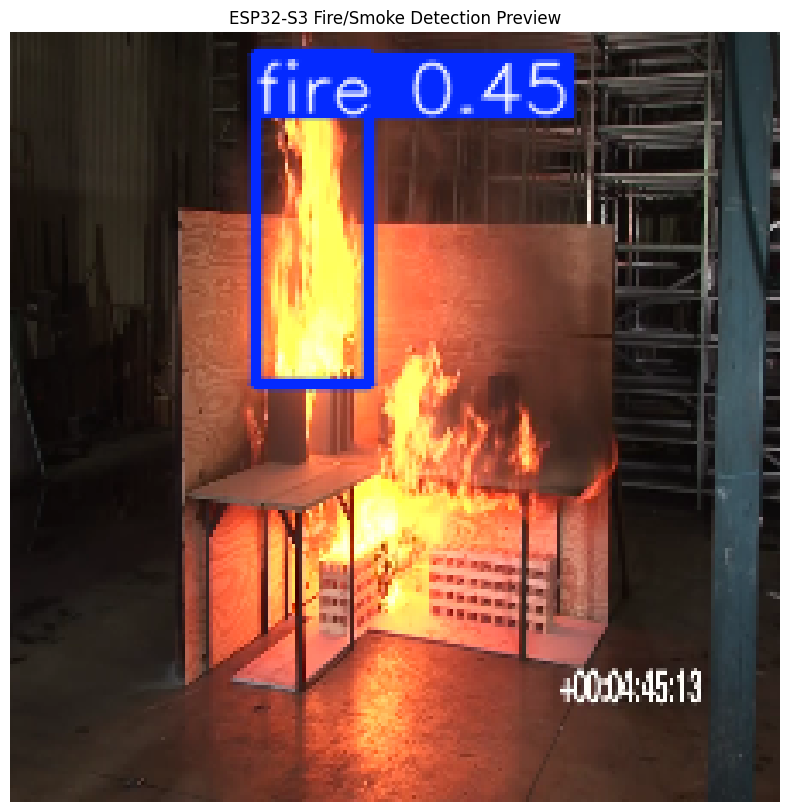

In [ ]:
from ultralytics import YOLO
import matplotlib.pyplot as plt
import cv2
import glob
import random

# 1. Load your champion PyTorch model
model = YOLO('/content/runs/detect/train/weights/best.pt')

# 2. Grab a random image from your test folder
test_images = glob.glob('/content/dataset/test/images/*.jpg') + glob.glob('/content/dataset/test/images/*.png')
sample_image = random.choice(test_images)

# 3. Run the prediction (conf=0.25 ignores weak guesses below 25% confidence)
results = model.predict(source=sample_image, conf=0.25)

# 4. Plot the bounding boxes onto the image array
res_plotted = results[0].plot()

# 5. Display the image using Matplotlib
plt.figure(figsize=(10, 10))
# Convert BGR to RGB so the colors display correctly in Colab
plt.imshow(cv2.cvtColor(res_plotted, cv2.COLOR_BGR2RGB))
plt.axis('off')
plt.title("ESP32-S3 Fire/Smoke Detection Preview")
plt.show()

In [ ]:
import glob
import random
import cv2
from google.colab.patches import cv2_imshow  # Colab's replacement for cv2.imshow
from ultralytics import YOLO

# 1. Load your champion PyTorch model
model = YOLO("/content/runs/detect/train/weights/best.pt")

# 2. Pick a random test image from your dataset
test_images = glob.glob("/content/dataset/test/images/*.jpg") + glob.glob(
    "/content/dataset/test/images/*.png"
)
sample_image = random.choice(test_images)

# 3. Run inference
results = model.predict(source=sample_image, conf=0.25)

# 4. Render and display the result inside Colab
annotated_frame = results[0].plot()
cv2_imshow(annotated_frame)

ModuleNotFoundError: No module named 'ultralytics'